# 01 · Exploratory Data Analysis on the complete data
**Project:** Noise-Robust Speech Recognition with Word-Level Error Detection (Group 9)

This notebook covers **all** of the data, not a sample:
- LibriSpeech: all 7 official splits, **292,367 utterances / 982 h**.
- MUSAN: all 2,016 files.
- ESC-50: all 2,000 clips.

`scripts/preprocess.py` decoded every file once and stored per-file statistics in manifests; this notebook reads those manifests.

| Role | Data |
|---|---|
| Training speech | LibriSpeech train-clean-100 |
| Model selection | dev-clean + dev-other |
| Final test | test-clean + test-other |
| Training noise | white, pink (synthetic) + MUSAN noise/music (90% of files) |
| **Held-out test noise** | **brown (synthetic) + ESC-50 (real environmental sounds)** |

In [1]:
import sys, json, warnings
from pathlib import Path
cwd = Path.cwd()
REPO = next(p for p in (cwd, *cwd.parents) if (p / "src" / "group9_ds_ai_lab").is_dir())
sys.path.insert(0, str(REPO / "src"))
from group9_ds_ai_lab.utils.paths import *   # noqa  (all project paths)
setup_env()
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Markdown, Audio
from group9_ds_ai_lab.utils.plotstyle import apply_style, SERIES, INK, INK2, GRID, SURF, MODEL_COLOR, MODEL_LABEL, NOISE_COLOR
apply_style(); warnings.filterwarnings("ignore")
pd.set_option("display.width", 200, "display.max_columns", 30, "display.float_format", "{:,.3f}".format)
print("repo:", REPO)

repo: <repo root>


In [2]:
ls = pd.read_parquet(MANIFESTS / "librispeech_all.parquet")
noise = pd.read_csv(MANIFESTS / "noise_files.csv")
qc = json.load(open(MANIFESTS / "qc_summary.json"))
ls["ls_split"] = pd.Categorical(ls["ls_split"], LS_SPLITS, ordered=True)
SPLIT_COLOR = dict(zip(LS_SPLITS, SERIES[:7]))
print(f"{len(ls):,} utterances, {ls.duration.sum()/3600:,.1f} hours, {ls.speaker_id.nunique():,} speakers")

292,367 utterances, 982.3 hours, 2,484 speakers


## 1. Corpus overview

In [3]:
g = ls.groupby("ls_split", observed=True)
overview = pd.DataFrame({"utterances": g.size(), "hours": g.duration.sum()/3600, "speakers": g.speaker_id.nunique(),
    "chapters": g.chapter_id.nunique(), "median_dur_s": g.duration.median(), "max_dur_s": g.duration.max(),
    "mean_words": g.n_words.mean(), "chars_per_s": g.chars_per_sec.mean()})
display(overview)

,utterances,hours,speakers,chapters,median_dur_s,max_dur_s,mean_words,chars_per_s
ls_split,,,,,,,,
train.clean.100,28539,100.591,251,585,13.995,24.525,34.693,14.542
train.clean.360,104014,363.606,921,2097,13.930,29.735,34.567,14.579
train.other.500,148688,496.858,1166,2784,13.630,27.920,32.403,14.158
validation.clean,2703,5.388,40,97,5.920,32.645,20.127,14.495
validation.other,2864,5.121,33,91,5.252,35.155,17.789,14.274
test.clean,2620,5.403,40,87,5.790,34.955,20.067,14.255
test.other,2939,5.342,33,90,5.150,34.510,17.810,13.803


## 2. Data-quality checks
All checks run on every file. Nothing needed repair, which is expected because LibriSpeech is curated.

In [4]:
checks = {k: qc[k] for k in ["total_utts","decode_failed","empty_text","non_16k","multi_channel","duplicate_ids",
                              "ctc_infeasible","text_changed_by_norm"]}
checks.update({"speaker overlap train/valid": qc["shared_speakers_train_valid"],
               "speaker overlap train/test": qc["shared_speakers_train_test"],
               "speaker overlap valid/test": qc["shared_speakers_valid_test"]})
display(pd.Series(checks, name="count").to_frame())

,count
total_utts,292367
decode_failed,0
empty_text,0
non_16k,0
multi_channel,0
duplicate_ids,0
ctc_infeasible,0
text_changed_by_norm,0
speaker overlap train/valid,0
speaker overlap train/test,0


## 3. Duration and speaking rate

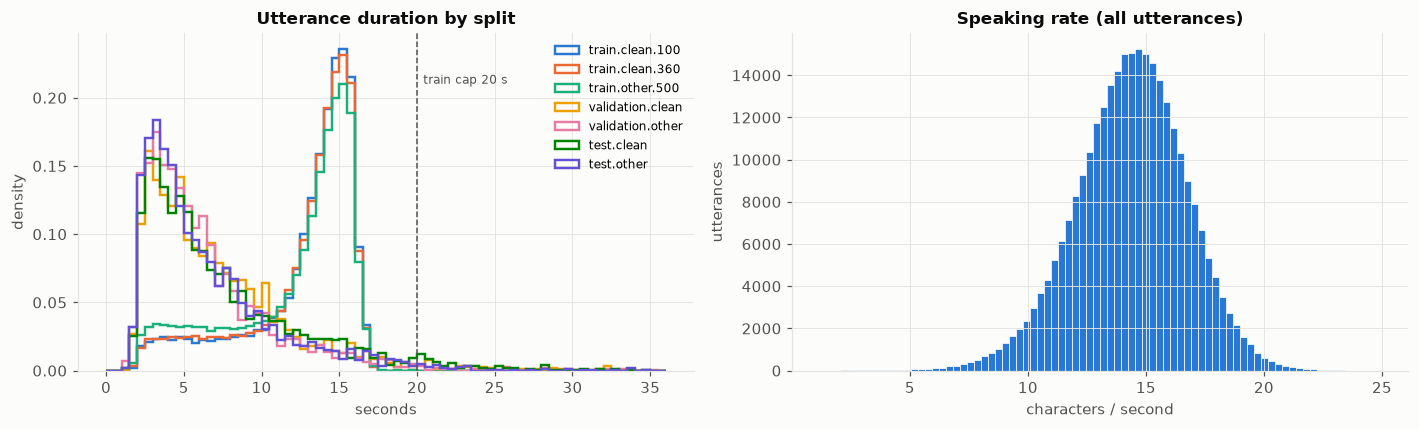

median 13.7s, 95% 16.1s, 99% 16.7s, max 35.2s; >20 s: 294 utts (0.10%) -> only 1 dropped from train-clean-100


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
bins = np.linspace(0, 36, 73)
for s in LS_SPLITS:
    axes[0].hist(ls.loc[ls.ls_split == s, "duration"], bins=bins, density=True, histtype="step", lw=1.6,
                 color=SPLIT_COLOR[s], label=s)
axes[0].axvline(20, color=INK2, ls="--", lw=1); axes[0].text(20.4, axes[0].get_ylim()[1]*.85, "train cap 20 s", color=INK2, fontsize=8)
axes[0].set(title="Utterance duration by split", xlabel="seconds", ylabel="density"); axes[0].legend(fontsize=8)
axes[1].hist(ls.chars_per_sec, bins=80, color=SERIES[0], edgecolor=SURF, lw=.5)
axes[1].set(title="Speaking rate (all utterances)", xlabel="characters / second", ylabel="utterances")
plt.tight_layout(); plt.show()
q = ls.duration.quantile([.5, .95, .99, 1])
print(f"median {q[.5]:.1f}s, 95% {q[.95]:.1f}s, 99% {q[.99]:.1f}s, max {q[1]:.1f}s; >20 s: {(ls.duration>20).sum()} utts "
      f"({(ls.duration>20).mean()*100:.2f}%) -> only {qc['train_dropped_too_long']} dropped from train-clean-100")

**Takeaways.**
- Training utterances are long (median about 14 s), while dev/test utterances are shorter (median about 5–6 s).
- Capping training clips at 20 s loses a single utterance and keeps GPU batches compact.
- Speaking rate is about 14.4 characters/s. At 50 encoder frames/s that leaves a lot of room for CTC alignment (Section 6).

## 4. Transcripts and vocabulary

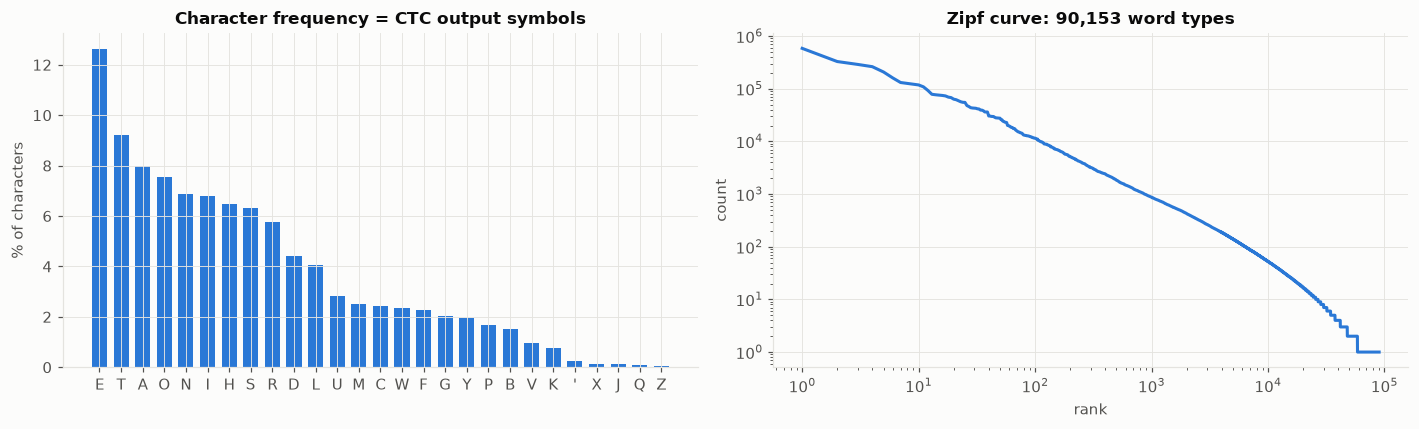

alphabet: 'ABCDEFGHIJKLMNOPQRSTUVWXYZ | apostrophes: 95,939


,split,tokens,oov_rate_vs_train100_%,oov_rate_vs_train960_%
0,validation.clean,54402,2.463,0.618
1,validation.other,50948,2.524,0.828
2,test.clean,52576,2.450,0.628
3,test.other,52343,2.784,0.835


In [6]:
import collections
chars = collections.Counter("".join(ls.text.str.replace(" ", "")))
ch = pd.Series(chars).sort_values(ascending=False); ch = 100 * ch / ch.sum()
words = collections.Counter(" ".join(ls.text).split())
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(ch.index, ch.values, color=SERIES[0], width=.7); axes[0].set(title="Character frequency = CTC output symbols", ylabel="% of characters")
freqs = np.array(sorted(words.values(), reverse=True))
axes[1].loglog(np.arange(1, len(freqs)+1), freqs, color=SERIES[0]); axes[1].set(title=f"Zipf curve: {len(words):,} word types", xlabel="rank", ylabel="count")
plt.tight_layout(); plt.show()
print("alphabet:", "".join(sorted(chars)), f"| apostrophes: {chars[chr(39)]:,}")
display(pd.read_csv(EDA / "oov_rates.csv"))

**Takeaways.**
- The transcripts use exactly 27 symbols (A–Z and the apostrophe), which the 32-token wav2vec2 character vocabulary covers. The apostrophe is **kept**; the M2/M3 pipeline removed it even though the model can output it.
- About 2.5% of test words never occur in the 100 h training text. We decode without a language model, so those words have to be spelled from sound alone.

## 5. Speakers

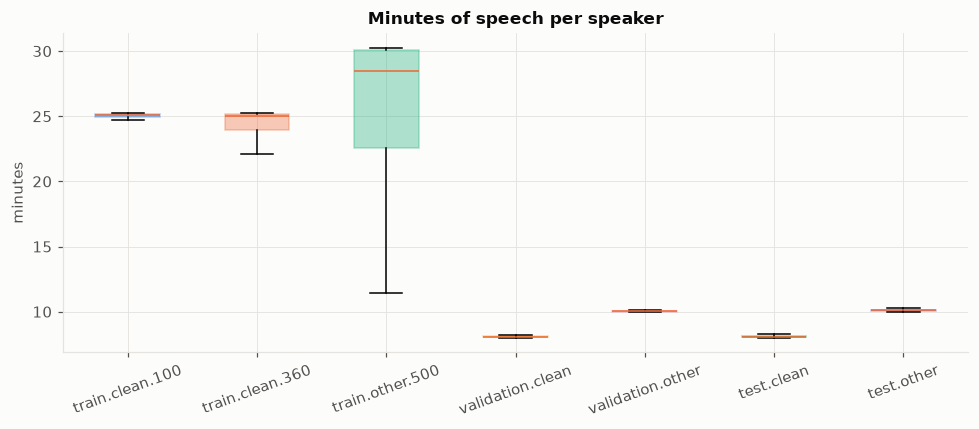

In [7]:
sp = ls.groupby(["ls_split", "speaker_id"], observed=True).duration.sum().div(60).reset_index()
fig, ax = plt.subplots(figsize=(9, 4))
bp = ax.boxplot([sp.loc[sp.ls_split == s, "duration"] for s in LS_SPLITS], tick_labels=LS_SPLITS, showfliers=False,
                patch_artist=True, widths=.5)
for p, s in zip(bp["boxes"], LS_SPLITS): p.set(facecolor=SPLIT_COLOR[s], alpha=.35, edgecolor=SPLIT_COLOR[s])
ax.set(title="Minutes of speech per speaker", ylabel="minutes"); ax.tick_params(axis="x", rotation=20); plt.tight_layout(); plt.show()

## 6. Signal quality and CTC feasibility

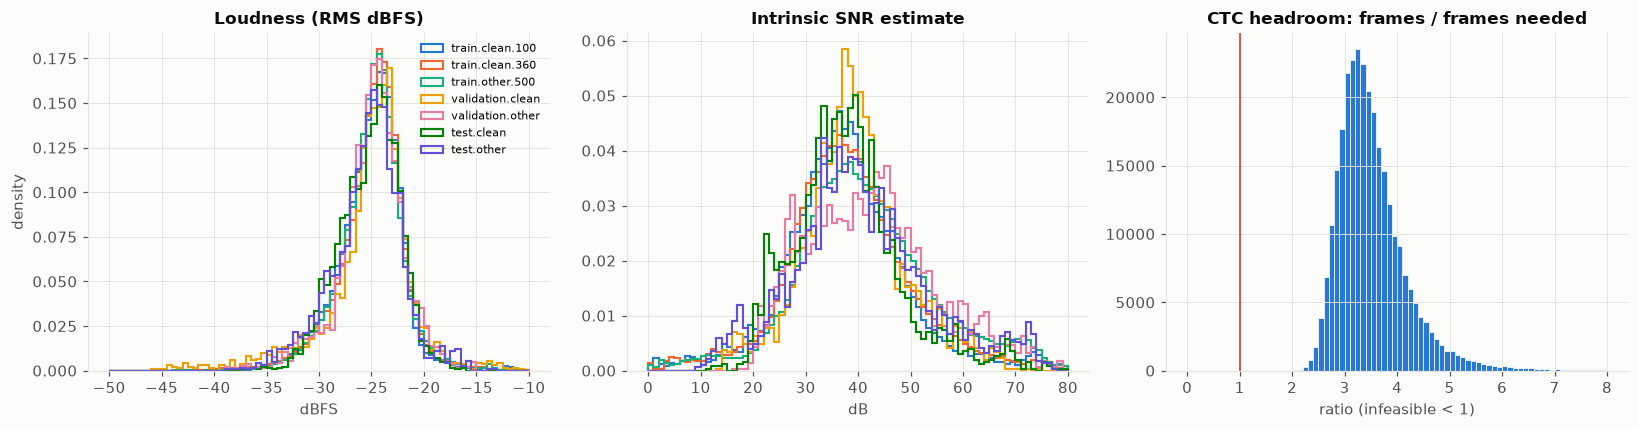

,ls_split,files_with_clipping,rms_dbfs,peak,clip_frac,lead_sil_s,trail_sil_s,active_ratio,est_snr_db
0,train.clean.100,131,-24.728,0.530,0.000,0.050,0.050,0.837,37.313
1,train.clean.360,562,-24.575,0.538,0.000,0.070,0.070,0.831,37.733
2,train.other.500,807,-24.716,0.529,0.000,0.170,0.130,0.801,40.567
3,validation.clean,2,-24.534,0.499,0.000,0.200,0.210,0.811,38.956
4,validation.other,1,-24.678,0.461,0.000,0.200,0.180,0.807,42.033
5,test.clean,11,-24.853,0.512,0.000,0.080,0.120,0.843,37.451
6,test.other,0,-25.045,0.453,0.000,0.170,0.190,0.801,39.764


CTC headroom: min 1.97x, median 3.40x -> every utterance is alignable


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for s in LS_SPLITS:
    d = ls[ls.ls_split == s]; kw = dict(histtype="step", density=True, lw=1.4, color=SPLIT_COLOR[s], label=s)
    axes[0].hist(d.rms_dbfs, bins=np.linspace(-50, -10, 81), **kw)
    axes[1].hist(d.est_snr_db, bins=np.linspace(0, 80, 81), **kw)
axes[0].set(title="Loudness (RMS dBFS)", xlabel="dBFS", ylabel="density"); axes[0].legend(fontsize=7)
axes[1].set(title="Intrinsic SNR estimate", xlabel="dB")
margin = ls.ctc_frames / ls.ctc_min_frames
axes[2].hist(margin, bins=np.linspace(0, 8, 81), color=SERIES[0], edgecolor=SURF, lw=.5); axes[2].axvline(1, color=SERIES[7], lw=1.2)
axes[2].set(title="CTC headroom: frames / frames needed", xlabel="ratio (infeasible < 1)")
plt.tight_layout(); plt.show()
display(pd.read_csv(EDA / "signal_quality_median.csv"))
print(f"CTC headroom: min {margin.min():.2f}x, median {margin.median():.2f}x -> every utterance is alignable")

**Takeaways.**
- Loudness varies by about 15 dB between utterances. So each input is z-normalised per utterance, and the SNR is set relative to that utterance's own power.
- The recordings themselves are clean in every split (an estimated 37–42 dB dynamic range). Added noise is therefore the variable we control.
- Every utterance has at least 1.97× the frames CTC needs.

## 7. Noise corpora

In [9]:
nz = noise.groupby(["corpus", "category"]).agg(files=("file", "size"), hours=("duration", lambda s: s.sum()/3600),
        orig_sr=("original_sample_rate", lambda s: sorted(s.unique())), median_rms_dbfs=("rms_dbfs", "median")).reset_index()
display(nz.groupby("corpus").head(3) if False else nz[nz.corpus == "musan"])
display(noise[noise.corpus == "musan"].groupby(["category", "role"]).size().unstack(fill_value=0))
esc = noise[noise.corpus == "esc50"]
print(f"ESC-50: {len(esc)} clips, {esc.category.nunique()} classes, original {esc.original_sample_rate.unique()} Hz -> 16 kHz; "
      f"{(esc.active_ratio < .5).mean()*100:.0f}% of clips are short bursty events")
display(pd.read_csv(EDA / "esc50_classes.csv").iloc[[0,1,2,3,4,-5,-4,-3,-2,-1]])

,corpus,category,files,hours,orig_sr,median_rms_dbfs
50,musan,music,660,42.615,[16000],-16.183
51,musan,noise,930,6.226,[16000],-19.799
52,musan,speech,426,60.449,[16000],-21.276


role,excluded_silent,train,unused,val
category,,,,
music,0,594,0,66
noise,1,836,0,93
speech,0,0,426,0


ESC-50: 2000 clips, 50 classes, original [44100] Hz -> 16 kHz; 21% of clips are short bursty events


,category,clips,median_active_ratio,median_rms_dbfs
0,can_opening,40,0.148,-27.800
1,sneezing,40,0.168,-24.360
2,glass_breaking,40,0.204,-27.238
3,door_wood_knock,40,0.385,-25.367
4,coughing,40,0.394,-25.765
45,train,40,1.000,-16.171
46,vacuum_cleaner,40,1.000,-14.171
47,pig,40,1.000,-17.308
48,washing_machine,40,1.000,-19.257
49,wind,40,1.000,-20.155


**Note (correction to the M2 report):** MUSAN contains about **42.6 h music / 60.5 h speech / 6.2 h noise**, not 7/7/6 h. MUSAN speech (babble) is out of scope and is not used.

## 8. Why brown noise is easy and ESC-50 is hard: spectra

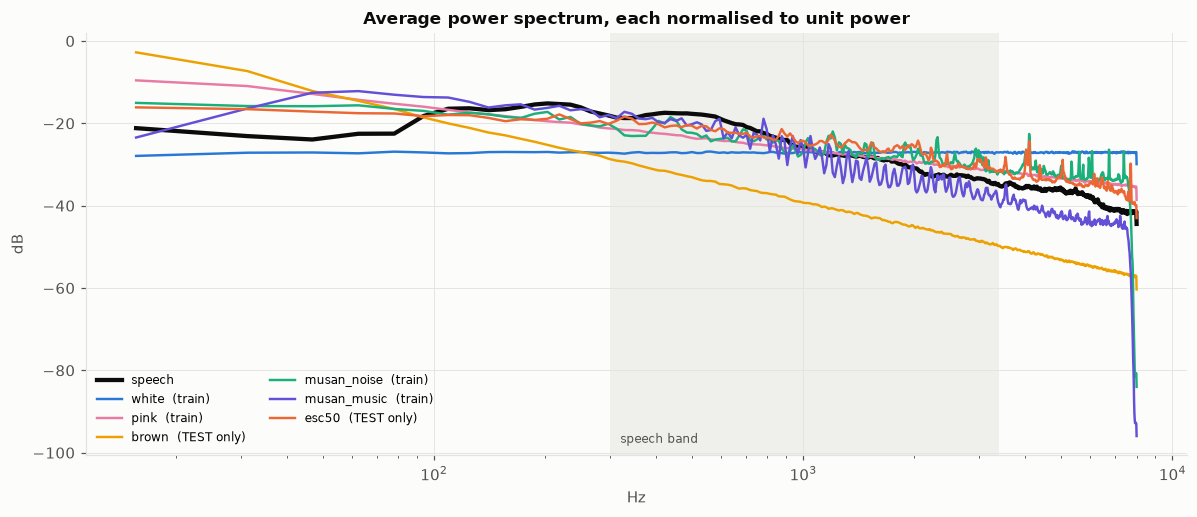

,% energy in 300-3400 Hz,% below 300 Hz
speech,59.557,35.170
white,38.707,3.723
pink,35.531,51.823
brown,2.350,97.518
musan_noise,48.069,33.846
musan_music,42.406,55.892
esc50,59.290,28.487


In [10]:
from group9_ds_ai_lab.data.audio import ArrowAudioReader
from group9_ds_ai_lab.data.noise import colored_noise, get_bank, apply_condition
from scipy.signal import welch
rng = np.random.default_rng(0); rd = ArrowAudioReader(); N = 16000 * 5
def mpsd(xs):
    acc = sum(welch(x / (np.sqrt(np.mean(x**2)) + 1e-9), 16000, nperseg=1024)[1] for x in xs); return acc / acc.sum()
f = welch(np.zeros(N), 16000, nperseg=1024)[0]
tr = ls[ls.ls_split == "train.clean.100"].sample(150, random_state=0)
spec = {"speech": mpsd([rd.load(s, r) for s, r in zip(tr.shard, tr.row)])}
for k in ("white", "pink", "brown"): spec[k] = mpsd([colored_noise(N, k, rng) for _ in range(10)])
spec["musan_noise"] = mpsd([get_bank("musan_noise_train").sample(N, rng)[0] for _ in range(100)])
spec["musan_music"] = mpsd([get_bank("musan_music_train").sample(N, rng)[0] for _ in range(100)])
spec["esc50"] = mpsd([get_bank("esc50_test").sample(N, rng)[0] for _ in range(200)])
fig, ax = plt.subplots(figsize=(11, 4.8))
for k, v in spec.items():
    ax.semilogx(f[1:], 10*np.log10(v[1:] + 1e-15), lw=2.8 if k == "speech" else 1.6, color=NOISE_COLOR.get(k, INK),
                label=k + ("  (TEST only)" if k in ("brown", "esc50") else "  (train)" if k != "speech" else ""))
ax.axvspan(300, 3400, color=GRID, alpha=.5, lw=0); ax.text(320, ax.get_ylim()[0]+3, "speech band", color=INK2, fontsize=8)
ax.set(title="Average power spectrum, each normalised to unit power", xlabel="Hz", ylabel="dB"); ax.legend(fontsize=8, ncol=2)
plt.tight_layout(); plt.show()
display(pd.DataFrame({k: {"% energy in 300-3400 Hz": 100*v[(f>=300)&(f<=3400)].sum(), "% below 300 Hz": 100*v[f<300].sum()}
                      for k, v in spec.items()}).T)

**Takeaways.**
- Brown noise has about 97% of its energy below 300 Hz, underneath the speech band. That explains the M3 result that brown noise barely hurts, even at 0 dB.
- ESC-50 puts as much energy in the speech band as speech itself (about 60%), so it is the meaningful **held-out, realistic** test.
- White noise covers the consonant-rich high frequencies, which makes it the most damaging synthetic noise per dB.

## 9. What the model hears: one utterance at 5 dB SNR

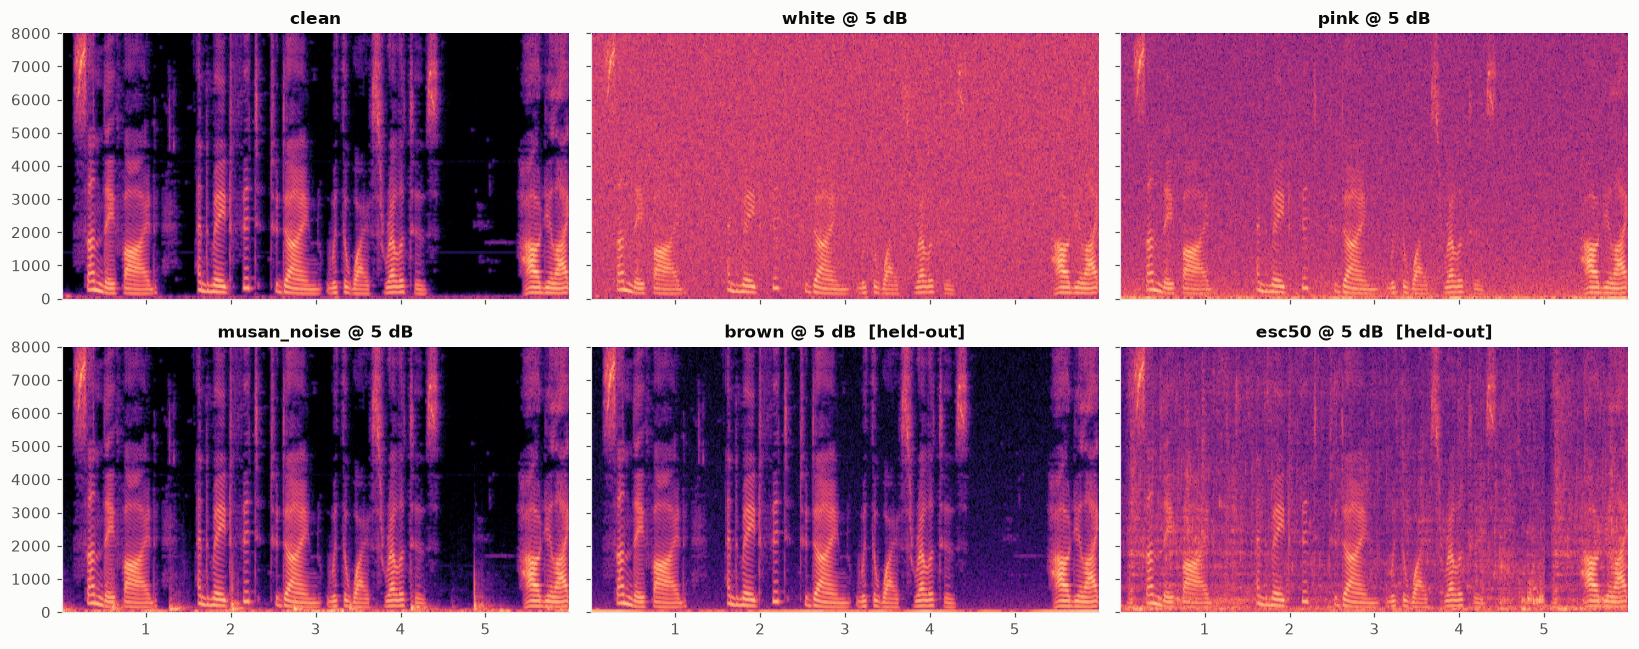

Transcript: SUNDAYFIED AND MADE FIT TO DINE WITH THE WIFE'S RELATIVES HOW'D YOU LIKE FOR ME TO BE THAT YOUNG FELLA MAMMA THE HUSBAND WHISPERED HE'S ONE OF THE SONS AND THERE AIN'T BUT TWO LEFT NOW


In [11]:
row = tr.iloc[3]; x = rd.load(row.shard, row.row)[: 16000 * 6]
conds = [("clean", None, "test"), ("white", 5, "train"), ("pink", 5, "train"), ("musan_noise", 5, "train"),
         ("brown", 5, "test"), ("esc50", 5, "test")]
fig, axes = plt.subplots(2, 3, figsize=(15, 6), sharex=True, sharey=True); clips = {}
for ax, (nt, snr, part) in zip(axes.ravel(), conds):
    y = x if nt == "clean" else apply_condition(x, nt, snr, 11, part=part)[0]; clips[nt] = y
    ax.specgram(y, NFFT=400, Fs=16000, noverlap=240, cmap="magma", vmin=-130, vmax=-30); ax.grid(False)
    ax.set_title(nt + ("" if snr is None else f" @ {snr} dB") + ("  [held-out]" if nt in ("brown", "esc50") else ""))
plt.tight_layout(); plt.show()
print("Transcript:", row.text)

In [12]:
for k, y in clips.items():
    display(Markdown(f"**{k}**")); display(Audio(y / (np.abs(y).max() + 1e-9), rate=16000))

**clean**

**white**

**pink**

**musan_noise**

**brown**

**esc50**